In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

In [23]:
# Load dataset
data = pd.read_csv("CC GENERAL.csv")
data.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [5]:
# Remove customer ID and handle missing values
data = data.drop(columns=["CUST_ID"])
data = data.fillna(data.mean())

In [7]:

# Standardize the data
scaled_data = StandardScaler().fit_transform(data)

In [9]:

# Apply PCA to reduce dimensions to 2
pca = PCA(n_components=2)
reduced_data = pca.fit_transform(scaled_data)

In [11]:
# Apply Agglomerative Hierarchical Clustering
model = AgglomerativeClustering(n_clusters=4)
clusters = model.fit_predict(reduced_data)


In [13]:
# Add cluster labels
data["Cluster"] = clusters

In [15]:
# Display cluster counts
print("Customers in each cluster:")
print(data["Cluster"].value_counts())

Customers in each cluster:
Cluster
2    4209
0    3232
1    1317
3     192
Name: count, dtype: int64


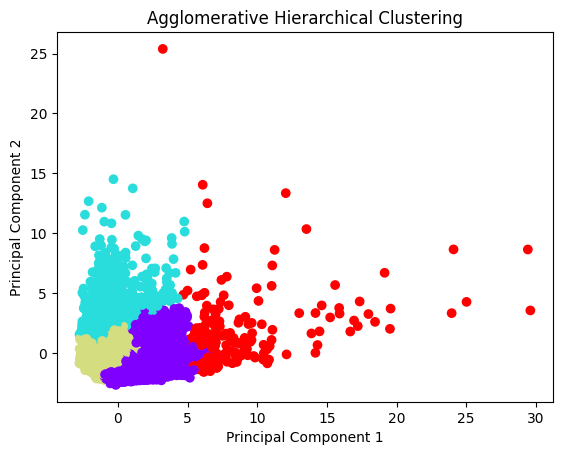

In [17]:
# Visualize clusters
plt.scatter(
    reduced_data[:, 0],
    reduced_data[:, 1],
    c=clusters,
    cmap="rainbow"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Hierarchical Clustering")
plt.show()

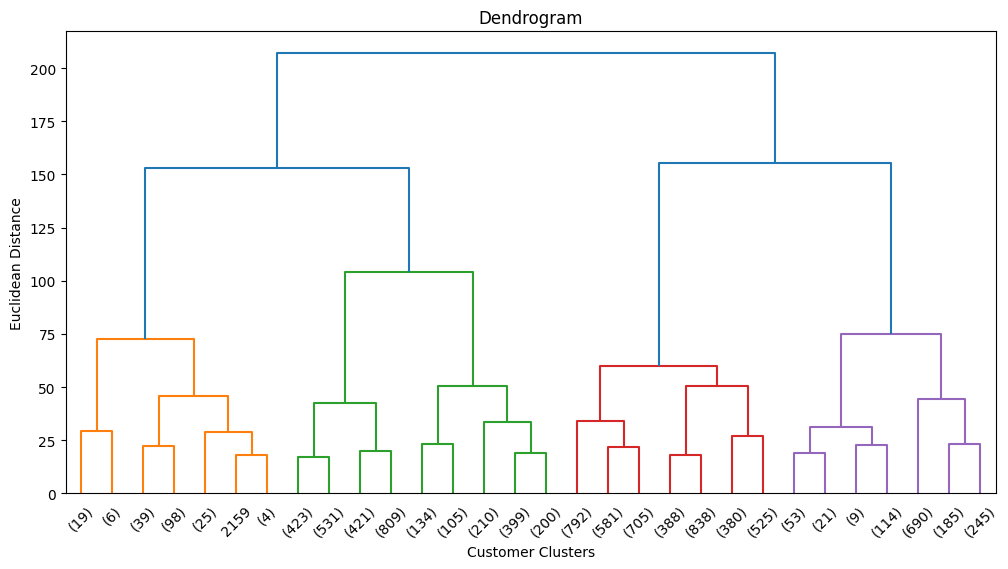

In [21]:
# Create linkage matrix
linkage_matrix = linkage(reduced_data, method="ward") 
#method="ward" uses Ward's linkage method. It merges clusters in a way that minimizes the increase in within-cluster variance.

# Plot dendrogram
plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30)
#truncate_mode="lastp" simplifies the dendrogram to show the final stages of merging.
# p=30 limits the display to the last 30 merged groups.
plt.title("Dendrogram")
plt.xlabel("Customer Clusters")
plt.ylabel("Euclidean Distance")
plt.show()